The model estimates **which action the carrier chooses at a frame**:
$\pi(s)=P(\mathrm{pass}\mid s)$ and $1-\pi(s)=P(\mathrm{carry}\mid s)$.
It models average observed behaviour, not an optimal policy or individual skill.
Pass completion and carry loss are estimated by separate execution models.
The action probabilities weight those risks in the composed next-action hazard.
The EPV decomposition motivates this separation [@fernandez2021]. **design choice**

## Native binary model

XGBoost supplies a score $f_\theta(z)$ and $\pi=\operatorname{sigmoid}(f_\theta(z))$.
Native `binary:logistic` learns the Bernoulli likelihood with pass=1 and carry=0:

$$-\sum_i\{y_i\log\pi_i+(1-y_i)\log(1-\pi_i)\}+\Omega(\theta).$$

The native gradient and curvature are $\pi_i-y_i$ and $\pi_i(1-\pi_i)$.
There are no nests or custom choice gradients in this classifier
[@chen2016xgboost]. It scores **one current state**, rather than the thousands
of candidate rows used by [pass destination choice](../03_transition_model/03_transition_model.ipynb).

## Benchmark features: four blocks

The final evaluated specification has **30 conceptual inputs: 28 numeric and
two raw categorical labels**. One-hot vocabulary is learned on fitting matches
only, with explicit missing and unseen levels. Granular start/previous labels
are retained, including literal `unknown`. The exact per-fold schemas are
[downloadable](../../data/benchmarks/action_selection/feature_schemas.json).

### 1. Context: five inputs

| Input | Definition |
|---|---|
| Start type | Raw event label for how this individual control began: reception, interception, recovery, restart, etc. |
| Previous action | Start context until a complete one-second carry has occurred; `ball_drive` thereafter. |
| Match minute | Match clock at the evaluated frame. |
| Score difference | Carrier-team goals minus opponent goals, using score changes known by that frame. |
| Completed carries | Number of full one-second carries already completed in the current individual possession. |

The count is an integer history summary; **fractional possession age is excluded**
because canonical carry samples occur at whole seconds while pass releases need
not. A pass at 0.4 s has count 0 and previous=start type. At 2.4 s it has count 2
and previous=`ball_drive`. No final possession length or remaining duration is
used. Role, player identity and provider-specific tactical phases are excluded.

### 2. Carrier and pressure: six inputs

| Input | Definition |
|---|---|
| Carrier x | Current longitudinal coordinate oriented toward its team's attack. |
| Carrier y | Current lateral coordinate under the same 180° orientation transform. |
| Carrier speed | Norm of current tracked velocity. |
| Velocity angle | Angle of velocity relative to attack, missing when effectively stationary. |
| Carry success | $D(s)=1-P(\mathrm{loss\ within\ 1s}\mid\mathrm{carry},s)$ from the physical likelihood. |
| BCOS | Probability-weighted accessible area in m² within 40 m, with arrival dispersion from the matching carry fit. |

The motion input is the existing centred seven-frame velocity estimate. The
carrier's local one-second projection is $x_B(1)=x_B(0)+v_B(0)$; no future
observed trajectory or observed acceleration is supplied. This is offline
evaluation: centred velocity smoothing has three future frames of support.
The [carry vignette](../01_ball_drive_risk/01_ball_drive_risk.ipynb) explains
the likelihood, and the [BCOS vignette](../extras/bcos/10_bcos.ipynb) introduces
the open-space concept [@bandara2025bcos]. Benchmark BCOS uses a 1 m target grid,
0.03125 m path spacing and 0.04 s integration, with carrier cap 6.6 m/s,
defender cap 7 m/s and linear/turning acceleration 7 m/s². The older optional API
example below uses a coarse demonstration configuration; it is not this cache.

### 3. Spatial and tactical state: eight inputs

Set $z=x_B(0)+v_B(0)\,1\mathrm{s}$. Lines are inferred from the **current**
tracked configuration; the projection does not use future observed positions.

| Input | Definition |
|---|---|
| Team xT after carry | Own-oriented xT at $z$. |
| Opponent xT after carry | Opponent-oriented xT at the same hypothetical point. |
| Team line index after carry | Nearest own-team line index at $z$. |
| Opponent line index after carry | Nearest opposition line index at $z$. |
| Team line distance after carry | Signed longitudinal distance from $z$ to the nearest own line; positive ahead in the carrier attack direction. |
| Opponent line distance after carry | Corresponding distance to the nearest opposition line. |
| Teammates ahead of carrier | Current teammates beyond the transverse line through the **current carrier**. |
| Opponents ahead of carrier | Current opponents beyond that same transverse line. |

Pressure lines use three complete-linkage clusters of longitudinal positions,
after removing padding and the historical extreme-x goalkeeper proxy. Their
nearest-centre indices are 1–3. Opponent indices follow the carrier attack axis;
own indices retain the opposite-axis convention shared with pass selection.
Both signed distances use the carrier attack axis. This line representation
is motivated by Fernández's feature family and aligned across this project
[@fernandez2021]. xT uses a smoothed 10×6 surface fitted to the same six matches
as the action classifier [@singh2018xt].

For a roster $G$ and point $z$, the ahead count is

$$N_G(z)=\sum_{i\in G}\mathbf1\{d x_i>d z_x\},\quad d\in\{-1,+1\}.$$

The carrier team's attack direction is used for **both rosters**. Exclude the
carrier and padding; retain tracked goalkeepers. Equality is not counted.
These are counts beyond a point, not players between pass origin and target.
A backward target can therefore have more players ahead.

### 4. Hypothetical passing options: eleven inputs

For each destination $j$ on the native one-metre pitch grid:

* $q_j=P(j\mid\mathrm{pass},s)$ comes from the flat destination-choice model,
  with its validation temperature. Its internal control feature is **raw**.
* $p_j=P(\mathrm{completion\ at}\ j\mid s)$ comes from pass physics **followed
  by isotonic calibration**. This action model uses calibrated pass risk, not
  raw pitch control, in its option summaries [@spearman2017; @spearman2018beyond].

Define $w_j^+=q_jp_j$ and $w_j^-=q_j(1-p_j)$.

| Input | Formula and meaning |
|---|---|
| Expected pass success | $\sum_jw_j^+$: completion averaged over likely destinations. |
| Team xT on success | $\sum_jw_j^+X_{own}(j)$: own threat retained through a completed pass. |
| Opponent xT on failure | $\sum_jw_j^-X_{opp}(j)$: opponent threat exposed by an unsuccessful pass. |
| Team line on success | $\sum_jw_j^+L_{own}(j)$. |
| Team line on failure | $\sum_jw_j^-L_{own}(j)$. |
| Opponent line on success | $\sum_jw_j^+L_{opp}(j)$. |
| Opponent line on failure | $\sum_jw_j^-L_{opp}(j)$. |
| Teammates ahead on success | $\sum_jw_j^+N_{own}(j)$. |
| Teammates ahead on failure | $\sum_jw_j^-N_{own}(j)$. |
| Opponents ahead on success | $\sum_jw_j^+N_{opp}(j)$. |
| Opponents ahead on failure | $\sum_jw_j^-N_{opp}(j)$. |

The four line and four count inputs are the agreed **4+4**. Each spatial value
is evaluated at a hypothetical target using current player locations, including
the failure branch. No observed recovery point is an input. **Do not divide by
total success/failure probability**: these are joint outcome-weighted summaries,
so branch probability is deliberately retained. **design choice**

## Canonical choices and arbitrary frames

The model can be queried at any usable carrier frame. Training uses full 1 s
successful carries, failed carries of any observed duration, and actual pass
releases. Successful short tails and extra hazard snapshots do not become
choice labels. A 2.4 s possession ending in a pass has AS rows at 0 (carry),
1 (carry), 2.4 (pass); frame 2 remains an additional hazard snapshot. A 0.4 s pass
contributes only its release choice. Outfield/no-shot and matched-endpoint
conventions are retained; no row is removed merely for unknown context.

## Visual explanation

The following sigmoid is a **synthetic illustration**, not a fitted prediction.
It shows how pass/carry probabilities become complementary mixture weights.


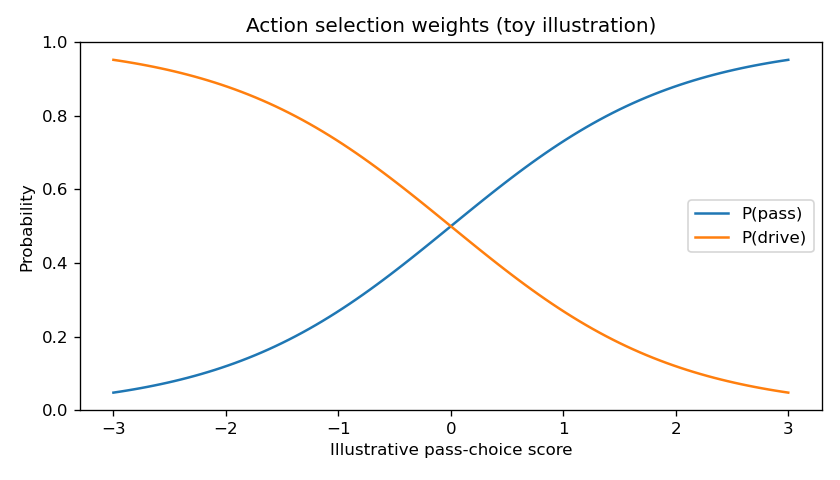

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Illustrative two-class probability curve for increasing pass attractiveness.
# This toy curve explains the mixture weight; it is not a model prediction.
pass_signal=np.linspace(-3,3,101); p_pass=1/(1+np.exp(-pass_signal)); p_drive=1-p_pass
fig,ax=plt.subplots(figsize=(7,4)); ax.plot(pass_signal,p_pass,label="P(pass)"); ax.plot(pass_signal,p_drive,label="P(drive)"); ax.set(xlabel="Illustrative pass-choice score",ylabel="Probability",ylim=(0,1),title="Action selection weights (toy illustration)"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_04_action_selection.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Public package API on a selected frame

**Deployment status:** the revised 30-input AS70 benchmark is complete, but the
installed `action_selection_model.json` still contains the historical production
booster and older schema. Its full-data refit and runtime alignment are separate
remaining work. This executable example demonstrates the current public
interface; **its outputs are not predictions from the AS70 ensemble**.

The inputs below are synthetic. The example initializes one match, selects a
team possession and frame 5 inside an action interval, computes components,
supplies a scalar BCOS value, and plots the state with the package function.
Small grids keep it quick and deliberately differ from benchmark settings.
Replace the demo loader with `PRESS.from_skillcorner(...)` from the
[match guide](../../usage.qmd) when using processed local matches.


{'Pass probability': 0.28229954838752747, 'Ball drive probability': 0.7177004516124725}


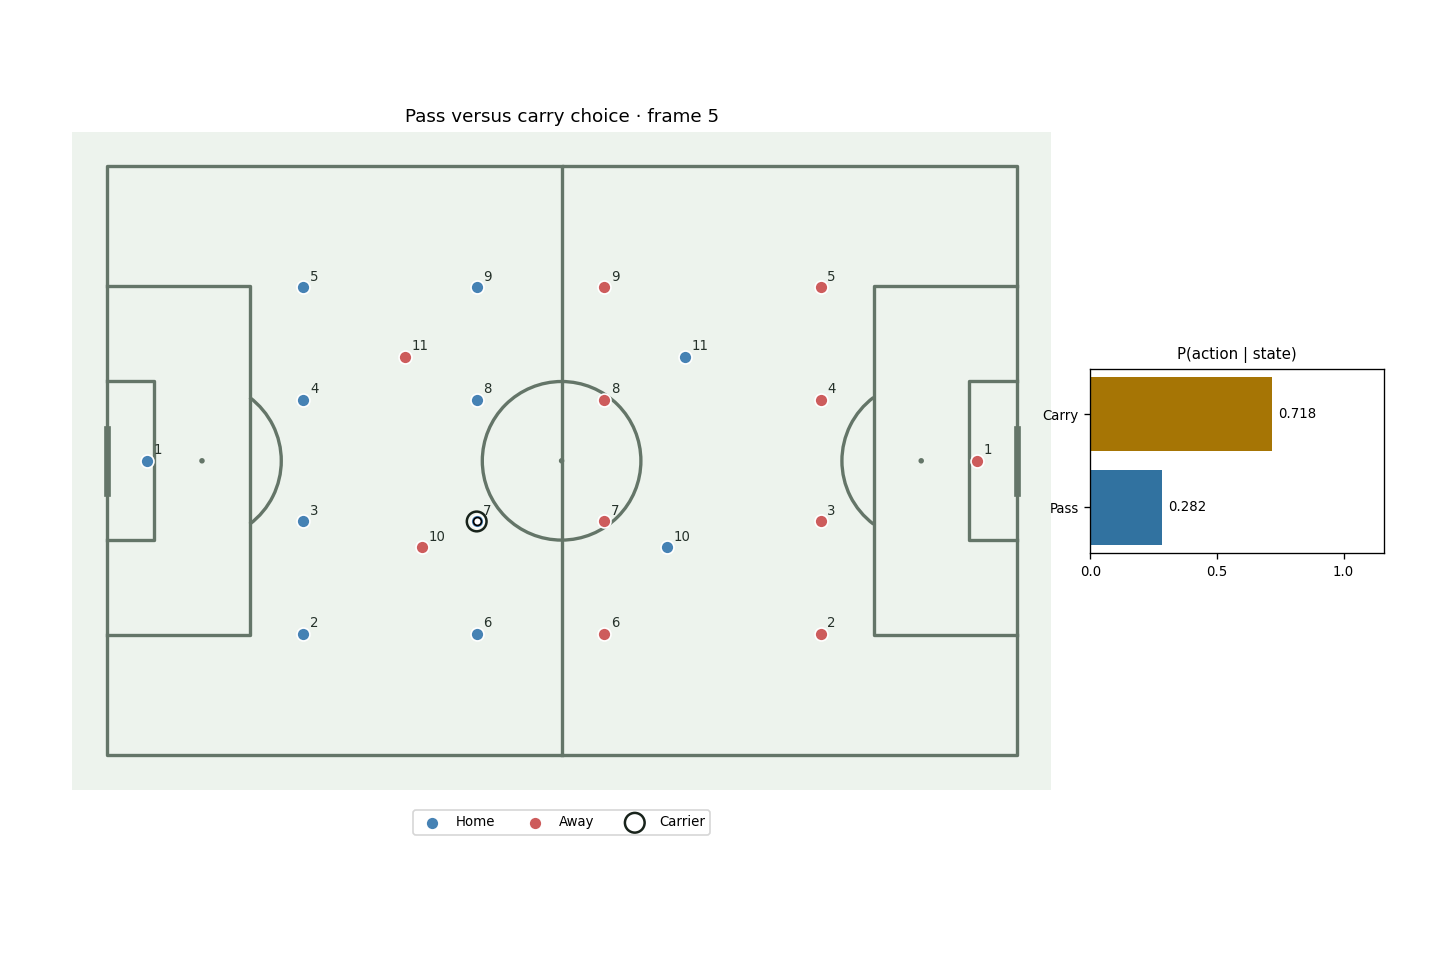

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid)
from PRESS.extras import BCOS
bcos = BCOS(tracking)
bcos_result = bcos.compute_bcos(frame_id, r_max=8, step=4)
bcos_value = float(np.asarray(bcos_result["Ball carrier open space"]).sum())
context = model.get_frame_context(frame_id)
p_pass = model.compute_action_selection_probability(
    frame_id, xT_grid, context["start_type"],
    context["previous_action"], bcos_value,
)
print(model.get_action_selection_result(frame_id))

from PRESS.visualization import plot_action_selection
fig, ax = plot_action_selection(model, frame_id)
out = Path("figures/vignette_04_action_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## Example: interpreting the 4+4 option summaries

Three hypothetical destinations suffice to illustrate the weighting. These
arrays are synthetic, not estimated choices or future observed outcomes.
Both branches use the same current-state spatial values at each target.


In [7]:
import pandas as pd

q = np.array([0.2, 0.5, 0.3])
p = np.array([0.9, 0.6, 0.8])
success, failure = q * p, q * (1 - p)
spatial = {
    "team_line": np.array([1, 2, 3]),
    "opponent_line": np.array([3, 2, 1]),
    "teammates_ahead": np.array([7, 4, 2]),
    "opponents_ahead": np.array([8, 5, 3]),
}
joint = pd.DataFrame({
    "success_weighted": {name: float(success @ value) for name, value in spatial.items()},
    "failure_weighted": {name: float(failure @ value) for name, value in spatial.items()},
})
assert np.isclose(success.sum(), 0.72)
for name, value in spatial.items():
    assert np.isclose(joint.loc[name].sum(), q @ value)
print(f"Expected pass success: {success.sum():.2f}")
print(joint.to_string())


Expected pass success: 0.72
                 success_weighted  failure_weighted
team_line                    1.50              0.60
opponent_line                1.38              0.52
teammates_ahead              2.94              1.06
opponents_ahead              3.66              1.34


## Benchmark and calibration

The final evaluation holds out two complete matches in each of five folds:
**6 fit + 2 validation + 2 test**. All learned physical/choice/xT inputs use the
matching fold's fits and saved upstream calibration; no full-ten-match refit
creates held-out features. Fitting-state upstream scores are in-sample, and the
two validation matches also support upstream calibration. The outer test stays
outside those fits. This is a development benchmark on ten previously studied
matches, not a fully independently nested or external evaluation.

All 144 grid configurations per fold are evaluated by validation logloss, with
native early stopping and no resampling. The primary probabilities are
uncalibrated classifier outputs. On 16,918 held-out decisions, CE is
**0.568592**, gain over the six-fit null **17.602%**, AUC **0.77083** and
ten-quantile ECE **1.026%**. This ECE is a weighted average of bin gaps,
not a guarantee of 1% error for every state or subgroup.

![Pooled action-choice calibration; temperature is a separate diagnostic.](../../figures/action_selection_pooled_calibration.png)

A validation-only temperature diagnostic gives ECE 0.817% and CE 0.568411,
with only +0.026 percentage points of null gain. The native model remains the
selected benchmark; the diagnostic does not alter installed weights
[@guo2017calibration]. Stalpaert reports CE 0.5762 with broad previous-action
categories and 0.4807 when specific **human-annotated** action types are included
(null 0.6602). Our result lies numerically between those references; equivalent
granular annotations are not available here [@stalpaert2022]. Fernández's
shoot/pass/carry classifier is not a direct binary numerical benchmark.

The following cell reads frozen **aggregate** results. The
[benchmark page](../../benchmark.qmd#action-selection-benchmark) documents the
grid, selected settings, cohort changes, published comparisons, context ablation
and calibration diagnostic in full.


In [9]:
scores = pd.read_csv("data/benchmarks/action_selection/metrics.csv")
print(scores[["model", "cross_entropy", "gain_on_null", "auc", "ece_quantile10"]].to_string(index=False))


                 model  cross_entropy  gain_on_null      auc  ece_quantile10
            native_raw       0.568592      0.176017 0.770834        0.010260
temperature_diagnostic       0.568411      0.176279 0.770923        0.008166
